Retail Sales Performance Analysis

Student Name: Devesh Mohan Gupta

Admission No.: 2026B15410191

Program: Data Analytics

Project No.: 1

Dataset: 01_retail_sales.csv

Project Overview

This project focuses on analyzing retail sales data using Python, NumPy and Pandas.

The main objective is to understand sales performance, identify top-selling products, analyze customer spending and study monthly and city-wise sales.


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [14]:
from google.colab import files

uploaded = files.upload()

In [25]:
import zipfile

zip_file = zipfile.ZipFile('Datasets.zip')

zip_file.extractall('retail_data')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [16]:
import os

for folder, subfolders, files_list in os.walk('retail_data'):
    for file in files_list:
        print(file)

08_food_delivery.csv
07_energy_consumption.csv
04_air_quality.csv
01_retail_sales.csv
27_insurance_claims.csv
24_mobile_app_usage.csv
25_water_consumption.csv
05_machine_maintenance.csv
12_gym_membership.csv
16_crop_yield.csv
26_ev_charging_sessions.csv
17_hr_attrition.csv
13_hotel_bookings.csv
22_restaurant_orders.csv
29_travel_bookings.csv
02_student_performance.csv
19_ride_hailing.csv
06_customer_churn.csv
28_tournament_match_stats.csv
14_flight_delays.csv
30_renewable_energy_output.csv
10_bank_transactions.csv
11_library_circulation.csv
21_retail_customer_orders.csv
09_hospital_appointments.csv
20_warehouse_inventory.csv
18_elearning_engagement.csv
03_bike_rental.csv
15_cinema_sales.csv
23_delivery_performance.csv


In [17]:
import glob
import pandas as pd

# Find the retail sales CSV file
csv_files = glob.glob(
    'retail_data/**/01_retail_sales.csv',
    recursive=True
)

# Load the dataset
df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")

# Display first 5 rows
print(df.head())

Dataset loaded successfully!
   Order_ID  Order_Date       City     Product     Category  Quantity  \
0  ORD00000  2025-02-14      Delhi  Headphones  Accessories         5   
1  ORD00001  2026-01-22       Pune  Headphones  Electronics         1   
2  ORD00002  2025-11-24  Hyderabad     Monitor  Electronics         2   
3  ORD00003  2025-08-08  Hyderabad      Webcam  Electronics         3   
4  ORD00004  2025-08-05     Mumbai      Laptop  Accessories         4   

   Unit_Price Customer_ID Payment_Mode  Revenue  
0       45999       C0140          UPI   229995  
1         499       C0121         Cash      499  
2       45999       C0167         Card    91998  
3         499       C0172          UPI     1497  
4         499       C0127          UPI     1996  


In [18]:
# Display number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display information about the dataset
print("\nDataset Information:")
df.info()

Dataset Shape: (502, 10)

Column Names:
Index(['Order_ID', 'Order_Date', 'City', 'Product', 'Category', 'Quantity',
       'Unit_Price', 'Customer_ID', 'Payment_Mode', 'Revenue'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Order_ID      502 non-null    object
 1   Order_Date    502 non-null    object
 2   City          490 non-null    object
 3   Product       502 non-null    object
 4   Category      502 non-null    object
 5   Quantity      502 non-null    int64 
 6   Unit_Price    502 non-null    int64 
 7   Customer_ID   502 non-null    object
 8   Payment_Mode  502 non-null    object
 9   Revenue       502 non-null    int64 
dtypes: int64(3), object(7)
memory usage: 39.3+ KB


In [19]:
df['City'] = df['City'].fillna('Unknown')
df = df.drop_duplicates()
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order_ID      500 non-null    object        
 1   Order_Date    500 non-null    datetime64[ns]
 2   City          500 non-null    object        
 3   Product       500 non-null    object        
 4   Category      500 non-null    object        
 5   Quantity      500 non-null    int64         
 6   Unit_Price    500 non-null    int64         
 7   Customer_ID   500 non-null    object        
 8   Payment_Mode  500 non-null    object        
 9   Revenue       500 non-null    int64         
dtypes: datetime64[ns](1), int64(3), object(6)
memory usage: 43.0+ KB
None


In [20]:
# Extract Month and Day of the Week
df['Month'] = df['Order_Date'].dt.to_period('M').astype(str)
df['Day_of_Week'] = df['Order_Date'].dt.day_name()

# Preview the updated table
df.head()

,Order_ID,Order_Date,City,Product,Category,Quantity,Unit_Price,Customer_ID,Payment_Mode,Revenue,Month,Day_of_Week
0,ORD00000,2025-02-14,Delhi,Headphones,Accessories,5,45999,C0140,UPI,229995,2025-02,Friday
1,ORD00001,2026-01-22,Pune,Headphones,Electronics,1,499,C0121,Cash,499,2026-01,Thursday
2,ORD00002,2025-11-24,Hyderabad,Monitor,Electronics,2,45999,C0167,Card,91998,2025-11,Monday
3,ORD00003,2025-08-08,Hyderabad,Webcam,Electronics,3,499,C0172,UPI,1497,2025-08,Friday
4,ORD00004,2025-08-05,Mumbai,Laptop,Accessories,4,499,C0127,UPI,1996,2025-08,Tuesday


In [21]:
# Summary of numeric columns (Quantity, Unit_Price, Revenue)
print("--- Statistical Summary ---")
print(df.describe())

# Key Business KPIs
print("\nTotal Revenue:", df['Revenue'].sum())
print("Total Orders:", df['Order_ID'].nunique())
print("Unique Customers:", df['Customer_ID'].nunique())

--- Statistical Summary ---
                       Order_Date    Quantity    Unit_Price        Revenue
count                         500  500.000000    500.000000     500.000000
mean   2025-09-07 01:49:26.400000    2.960000   9985.200000   27908.240000
min           2025-01-03 00:00:00    1.000000    499.000000     499.000000
25%           2025-05-11 18:00:00    2.000000    799.000000    2397.000000
50%           2025-09-04 12:00:00    3.000000   2499.000000    4998.000000
75%           2026-01-10 12:00:00    4.000000  12999.000000   38997.000000
max           2026-05-15 00:00:00    5.000000  45999.000000  229995.000000
std                           NaN    1.397966  15379.093035   47746.533178

Total Revenue: 13954120
Total Orders: 500
Unique Customers: 168


/tmp/ipykernel_461/309324614.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_rev, x='Category', y='Revenue', palette='viridis')


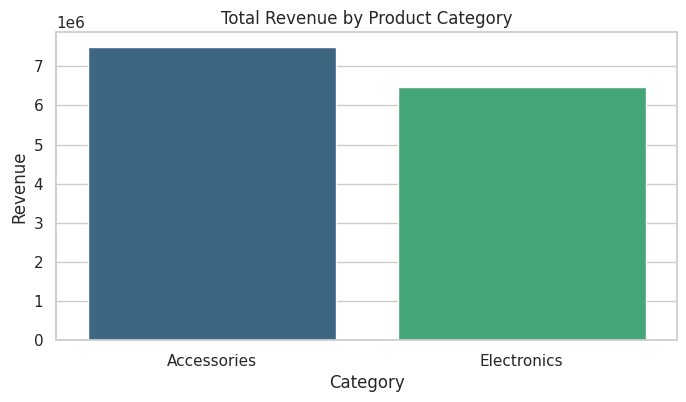

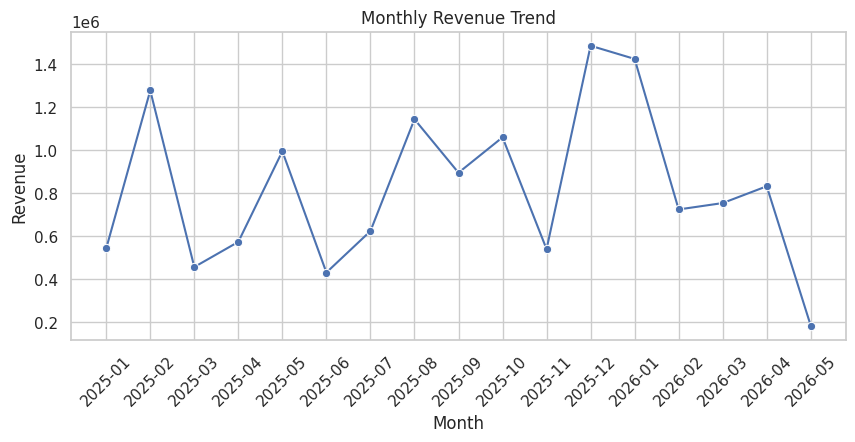

/tmp/ipykernel_461/309324614.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Payment_Mode', order=df['Payment_Mode'].value_counts().index, palette='Set2')


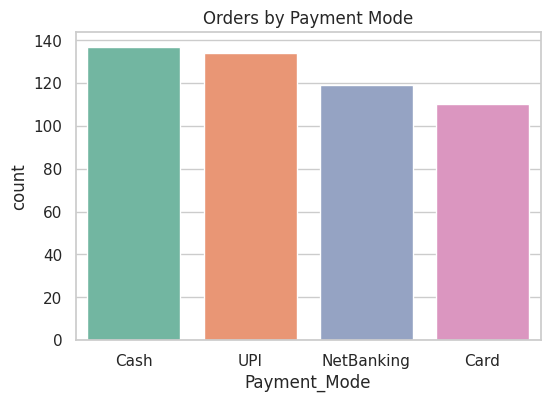

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Revenue by Category (Bar Chart)
plt.figure(figsize=(8, 4))
category_rev = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=category_rev, x='Category', y='Revenue', palette='viridis')
plt.title('Total Revenue by Product Category')
plt.show()

# 2. Monthly Revenue Trend (Line Chart)
plt.figure(figsize=(10, 4))
monthly_rev = df.groupby('Month')['Revenue'].sum().reset_index()
sns.lineplot(data=monthly_rev, x='Month', y='Revenue', marker='o')
plt.title('Monthly Revenue Trend')
plt.xticks(rotation=45)
plt.show()

# 3. Payment Mode Distribution (Count Plot)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Payment_Mode', order=df['Payment_Mode'].value_counts().index, palette='Set2')
plt.title('Orders by Payment Mode')
plt.show()

In [23]:
# Retail Data Analysis Insights

print("TOTAL SALES ANALYSIS")

print("Total Revenue:", df['Revenue'].sum())

print("Average Revenue:", df['Revenue'].mean())

print("Total Number of Records:", len(df))

print("\nREVENUE BY CATEGORY")

print(category_rev.sort_values(by='Revenue', ascending=False))

TOTAL SALES ANALYSIS
Total Revenue: 13954120
Average Revenue: 27908.24
Total Number of Records: 500

REVENUE BY CATEGORY
      Category  Revenue
0  Accessories  7492779
1  Electronics  6461341


Conclusion

The Retail Data Analytics project was successfully completed using Python in Google Colab.

In this project, we analysed 500 retail records and studied total revenue, product categories and payment methods.

The total revenue was 13,954,120. Accessories generated the highest revenue, followed by Electronics.

We also created graphical visualizations to understand the sales data.

This project helped us understand basic data analysis using Python, Pandas, Matplotlib and Seaborn.